In [1]:
# for package auto reload
%load_ext autoreload
%autoreload 2

# for better rendering of plots in jupyter notebook
%matplotlib inline

In [2]:
# for ml
from sklearn.linear_model import LinearRegression

In [4]:
# base modules
from pathlib import Path

# for manipulating data
import numpy as np
import pandas as pd

# forMachine Learning
from sklearn.ensemble import RandomForestRegressor

#for plots
import seaborn as sns


In [5]:
# base modules
from pathlib import Path
import logging
from collections import OrderedDict

# for manipulating data
import numpy as np
import pandas as pd
import math
import dill

# for Machine Learning
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn import metrics
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV

# for visualization
from matplotlib import pyplot as plt

In [6]:
from eclyon.transforms import (
    add_date_columns, 
    change_columns_from_str_to_categorical, 
    process_df,
)

### Visualize the data

In [7]:
df_raw = pd.read_csv('data.csv')

In [8]:
def display_all(df):
    with pd.option_context("display.max_rows", 50, "display.max_columns", 50): 
        display(df)

In [9]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

In [10]:
df_raw = df_raw.convert_dtypes()

In [11]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  string 
 1   Customer Type                      129880 non-null  string 
 2   Age                                129880 non-null  Int64  
 3   Type of Travel                     129880 non-null  string 
 4   Class                              129880 non-null  string 
 5   Flight Distance                    129880 non-null  Int64  
 6   Inflight wifi service              129880 non-null  Int64  
 7   Departure/Arrival time convenient  129880 non-null  Int64  
 8   Ease of Online booking             129880 non-null  Int64  
 9   Gate location                      129880 non-null  Int64  
 10  Food and drink                     129880 non-null  Int64  
 11  Online boarding                    1298

In [13]:
df_raw.columns


Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [14]:
df_raw.shape

(129880, 22)

In [15]:
df_raw.satisfaction

0         False
1         False
2          True
3         False
4          True
          ...  
129875    False
129876     True
129877    False
129878     True
129879    False
Name: satisfaction, Length: 129880, dtype: boolean

In [26]:
satisfaction = df_raw.satisfaction.tolist()


### Preprocessing the data

In [28]:
df_transformed = change_columns_from_str_to_categorical(df_raw)

In [23]:
df_transformed.Gender.dtype

CategoricalDtype(categories=['Female', 'Male'], ordered=True, categories_dtype=string)

In [24]:
df_transformed.Gender.cat.categories.tolist()

['Female', 'Male']

### Taking care of missing values 

In [35]:
display_all(df_transformed.isnull().sum().T) 

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

In [36]:
df_transformed.isnull().describe()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
count,129880,129880,129880,129880,129880,129880,129880,129880,129880,129880,...,129880,129880,129880,129880,129880,129880,129880,129880,129880,129880
unique,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,2,1
top,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
freq,129880,129880,129880,129880,129880,129880,129880,129880,129880,129880,...,129880,129880,129880,129880,129880,129880,129880,129880,129487,129880


In [38]:
display_all(df_transformed.isnull().sum().sort_index()/len(df_transformed))

Age                                  0.000000
Arrival Delay in Minutes             0.003026
Baggage handling                     0.000000
Checkin service                      0.000000
Class                                0.000000
Cleanliness                          0.000000
Customer Type                        0.000000
Departure Delay in Minutes           0.000000
Departure/Arrival time convenient    0.000000
Ease of Online booking               0.000000
Flight Distance                      0.000000
Food and drink                       0.000000
Gate location                        0.000000
Gender                               0.000000
Inflight entertainment               0.000000
Inflight wifi service                0.000000
Leg room service                     0.000000
On-board service                     0.000000
Online boarding                      0.000000
Seat comfort                         0.000000
Type of Travel                       0.000000
satisfaction                      

In [35]:
df_cleaned = df_raw.fillna(0)

In [36]:
display_all(df_cleaned.isnull().sum().T) 

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [37]:
df_cleaned.shape

(129880, 22)

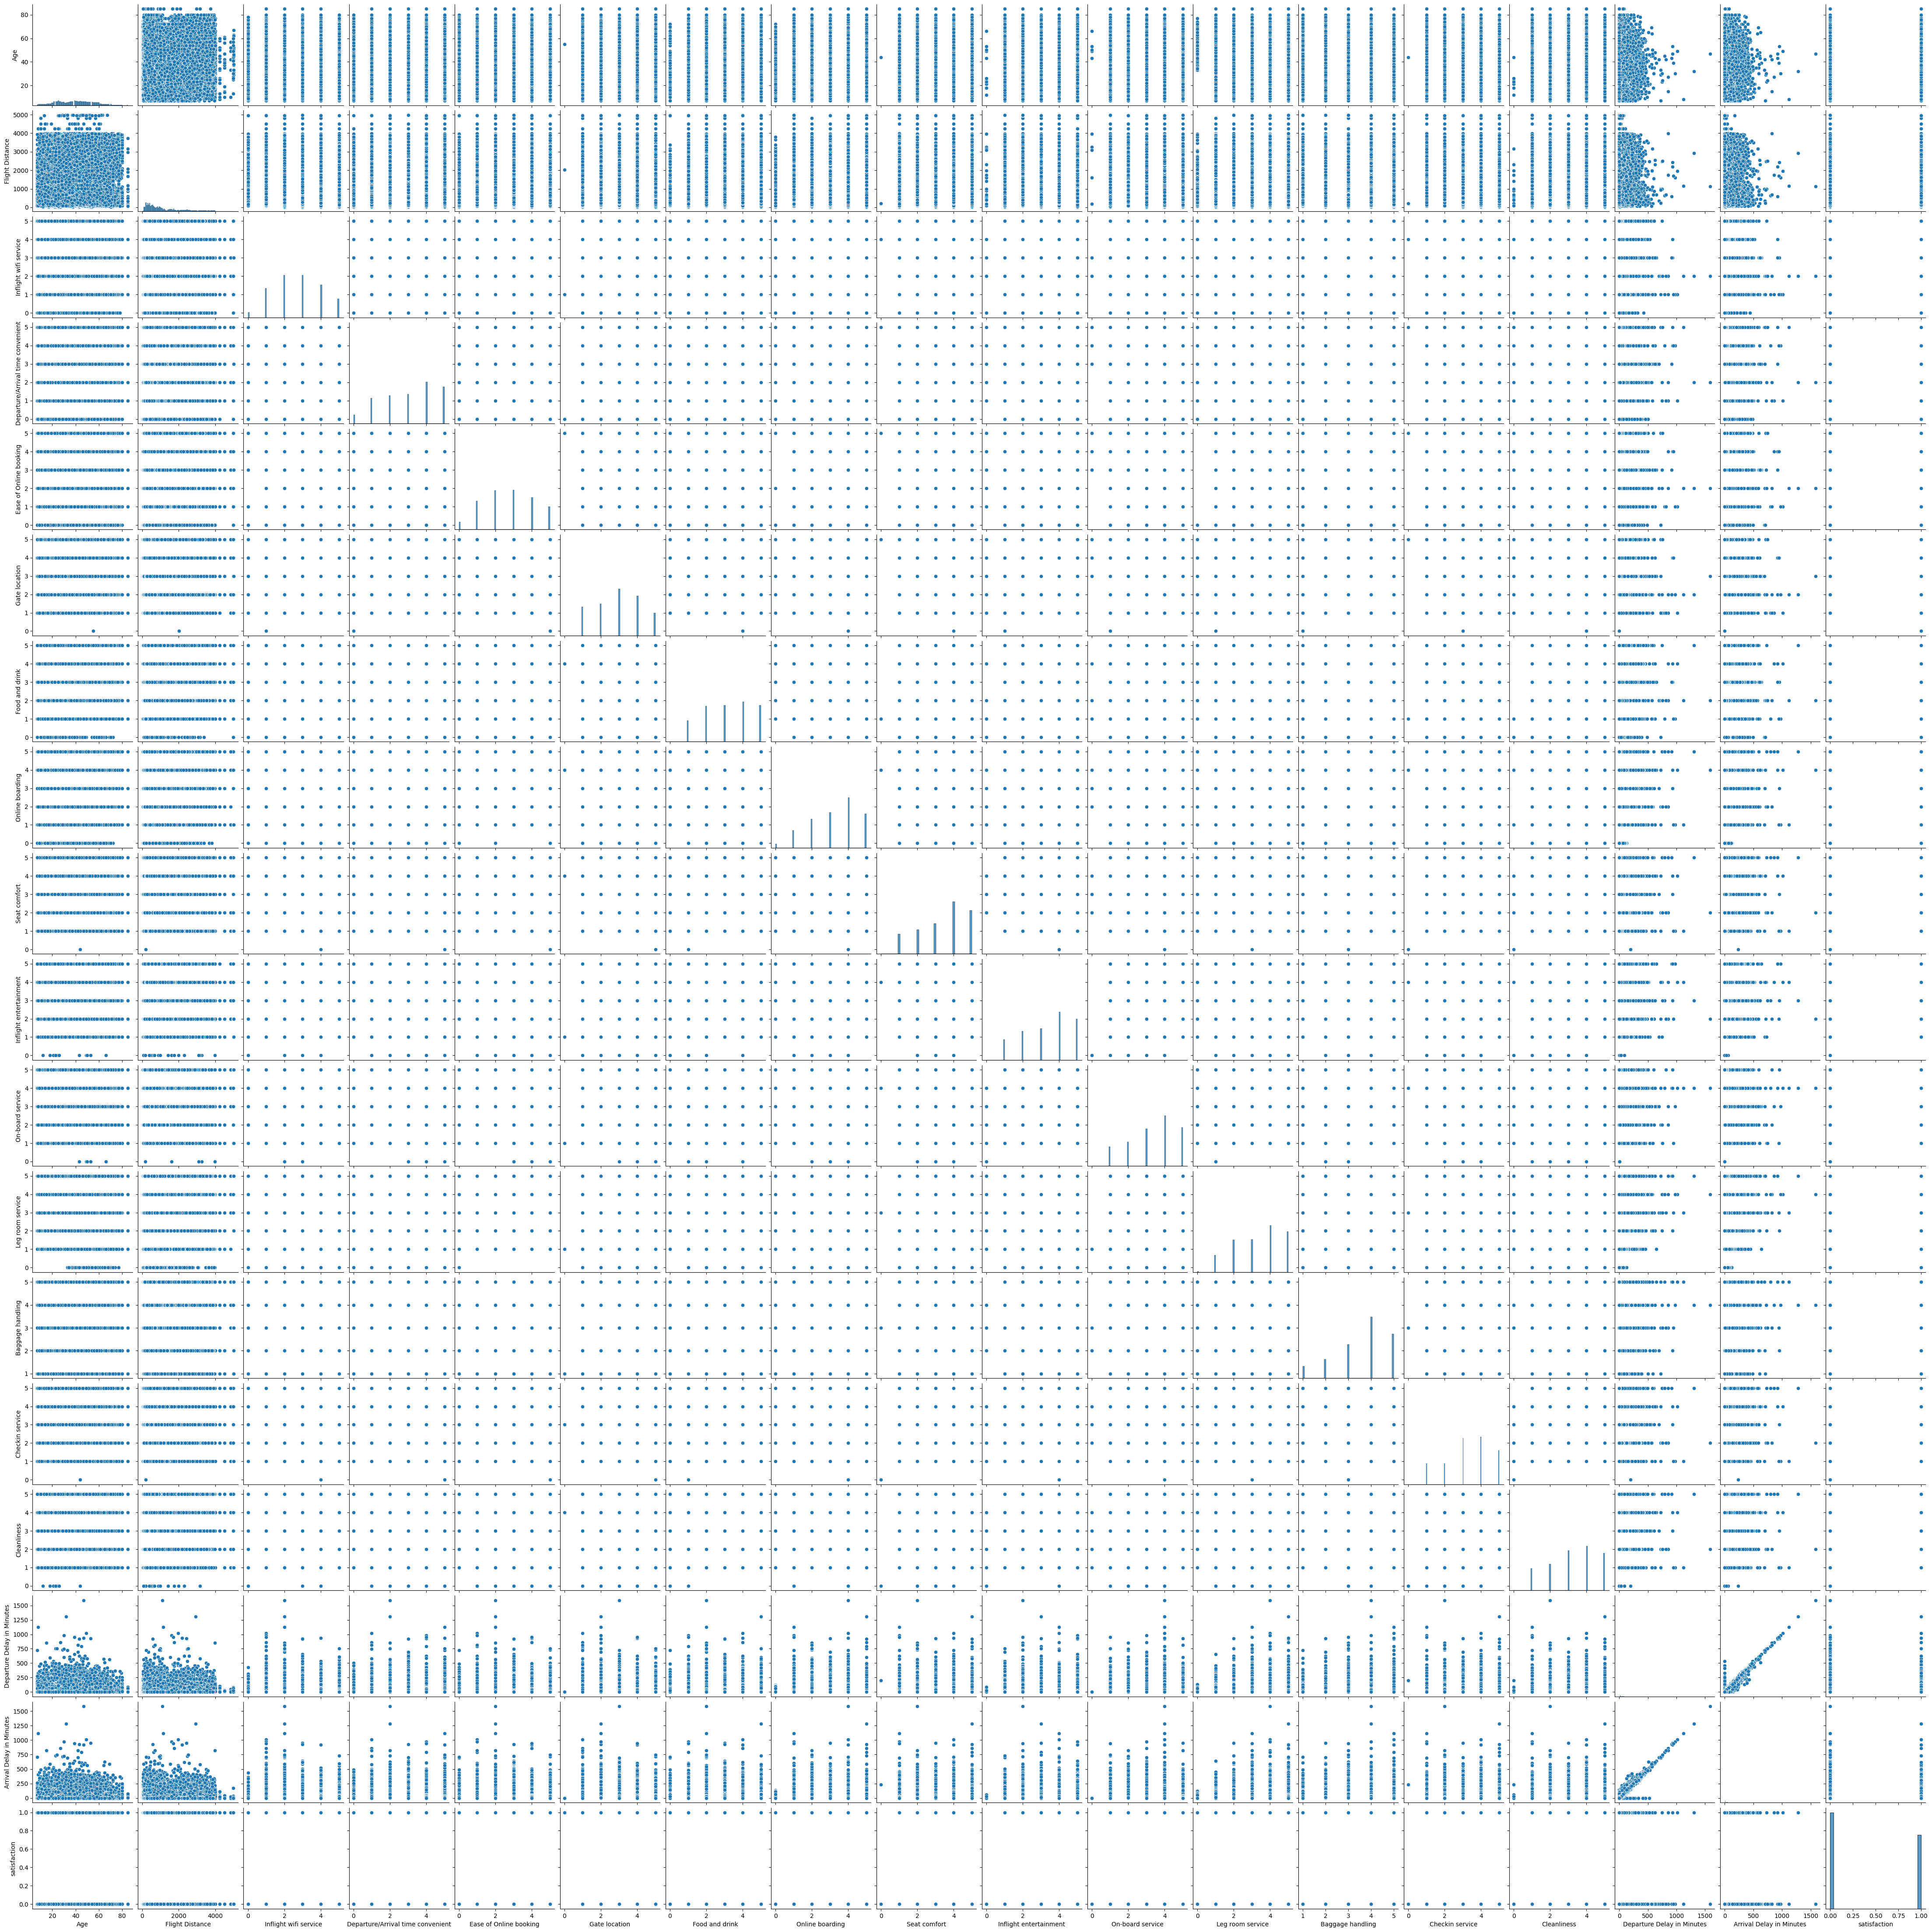

In [ ]:
#sns.pairplot(df_cleaned)